## <font color = #0288d1>一元线性回归ANN</font>
### <font color="purple">**我们使用最简单的线性模型**</font>
### $$ y=kx+b+ε $$

+ ### 其中k是斜率，b是截距，最后的ε是测量误差。
+ ### 现在假设k=3，b=-2，然后据此产生100个模拟的数据：


In [ ]:
import numpy as np

true_b = -1
true_k = 3
N = 100
# 数据生成
np.random.seed(23)
x = np.random.rand(N, 1)
x

In [4]:
type(x)

numpy.ndarray

In [5]:
epsilon = 0.1 * np.random.randn(N, 1)
y = true_b + true_k * x + epsilon

In [6]:
y

array([[ 0.64399324],
       [ 2.03419679],
       [ 1.21684296],
       [-0.25396599],
       [-0.12178592],
       [ 1.10118026],
       [-0.45446724],
       [ 0.09558347],
       [ 0.89794629],
       [ 0.24576261],
       [-0.98606475],
       [ 1.77453961],
       [ 1.57788271],
       [-0.07955896],
       [ 0.59642029],
       [ 1.98140667],
       [ 1.42674479],
       [-0.62243586],
       [-0.24905296],
       [ 0.02754245],
       [ 1.38510515],
       [ 0.7187382 ],
       [-0.64591568],
       [-0.97502377],
       [ 1.73177645],
       [-0.70165535],
       [ 0.025803  ],
       [ 0.00614092],
       [ 1.64370693],
       [ 0.08301936],
       [ 1.49939608],
       [ 1.31387893],
       [-0.81875128],
       [ 0.84580291],
       [-0.5558523 ],
       [-0.82891122],
       [ 1.52597033],
       [ 0.2828375 ],
       [-0.46890297],
       [ 0.80567108],
       [ 0.73122097],
       [ 1.25849087],
       [ 0.76605556],
       [ 0.86020968],
       [-0.27793839],
       [-0

In [7]:
y[78][0]


np.float64(0.01739961025386583)

In [8]:
np.random.rand(3)

array([0.41065096, 0.18415932, 0.09317831])

### **<font color=purple>数据准备</font>**

+ ### 随后，需要把这些数据分成<font color="purple">**2部分**</font>，一部分用于<font color="purple">**训练**</font>，另外一部分用于<font color="purple">**验证**</font>训练的效果。
+ ### 在此，随机抽取80个数据作为训练数据，剩下20个数据作为验证数据：

In [9]:
# 索引乱序
idx = np.arange(N)
idx

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])

In [10]:
np.random.shuffle(idx)
idx

array([ 8, 84, 63, 76, 15, 19, 44, 71,  0, 93, 11,  6, 85, 10, 37, 24,  1,
       59, 86, 73, 87,  4, 30, 61, 67, 17, 52, 91, 98, 23, 97, 88, 74, 81,
       14, 92, 16, 39, 83, 62, 69, 38,  7, 77, 21, 90, 53,  3, 33, 18, 20,
       47, 46, 22, 34, 25, 58, 40, 36, 70, 48, 64, 78, 45,  9, 29, 50, 72,
       96, 26, 66, 41, 75, 54, 79, 65,  5, 42, 99,  2, 13, 56, 94, 68, 82,
       55, 12, 60, 51, 27, 32, 28, 89, 57, 31, 43, 95, 35, 49, 80])

In [11]:
# 使用80个随机的数据用作训练
train_idx = idx[: int(N * 0.8)]
# 剩余的20个数据用作验证
val_idx = idx[int(N * 0.8) :]


# 产生训练和验证数据集
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]

In [12]:
x_train.size

80

### matplotlib 默认字体是 `DejaVu Sans`，**不包含中文字符**
#### 安装字体（ubuntu）
sudo apt update  
sudo apt install fonts-wqy-microhei

```
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False
```

In [13]:
import matplotlib.pyplot as plt


def figure1(x_train, y_train, x_val, y_val):
    """分别画出训练集和验证集的散点图，查看数据集分布。"""

    # 创建一个包含两个子图的画布，一行 2 张子图
    # 画布大小，宽 12 英寸，高 6 英寸
    # 返回：fig 整个画布对象，ax 是包含两个子图的数组，ax[0] 左边子图，ax[1] 右边子图
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    # 离散样本点，c='g' 颜色 green 绿色
    ax[0].scatter(x_train, y_train, c="g")
    ax[0].set_xlabel("x")
    ax[0].set_ylabel("y")

    # 固定 y 轴范围：y 轴最小 -1，最大 2.1，避免两张图坐标轴缩放不一样，方便对比。
    ax[0].set_ylim((-1, 2.1))
    ax[0].set_title("生成的数据 - 训练集")

    # 右边子图
    ax[1].scatter(x_val, y_val, c="r")
    ax[1].set_xlabel("x")
    ax[1].set_ylabel("y")
    ax[1].set_ylim((-1, 2.1))
    ax[1].set_title("生成的数据 - 验证集")
    fig.tight_layout()

    return fig, ax

C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\2150836790.py:27: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\2150836790.py:27: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\2150836790.py:27: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\2150836790.py:27: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\2150836790.py:27: UserWarning: Glyph 25454 (\N{CJK UNIFIED IDEOGRAPH-636E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipyker

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': '生成的数据 - 训练集'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': '生成的数据 - 验证集'}, xlabel='x', ylabel='y'>],
       dtype=object))

C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\

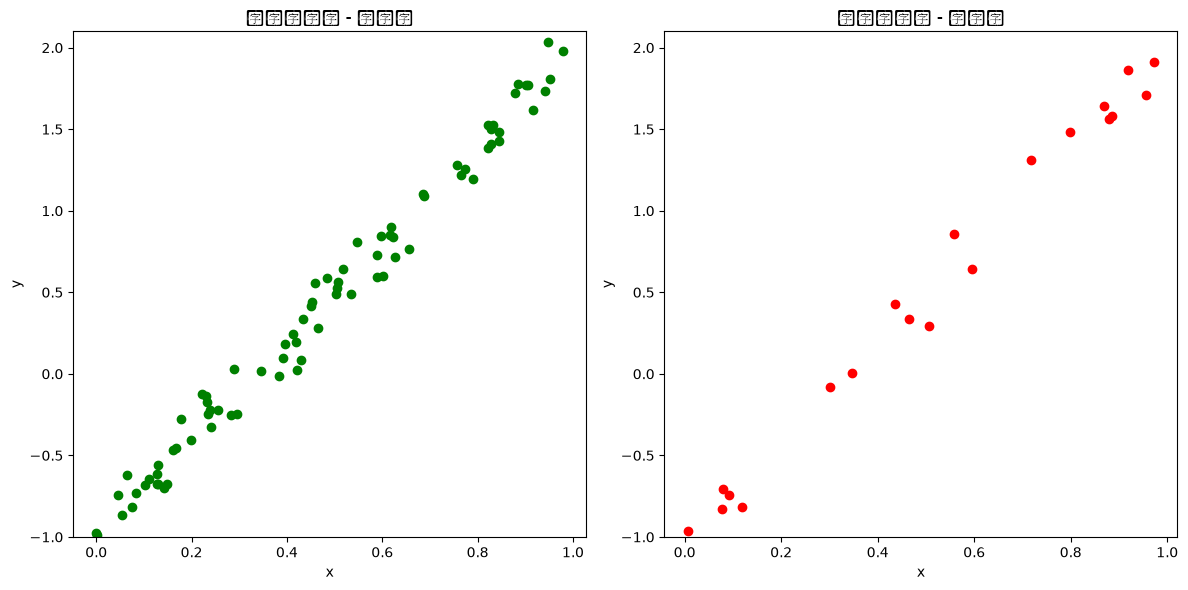

In [14]:
figure1(x_train, y_train, x_val, y_val)

### **<font color=purple>随机初始化</font>**

+ ### 需要计算（或者说是训练）的参数是<font color="purple">**k和b**</font>。
+ ### 一开始，通过随机函数给出一个随机的初始值：
> ### 一开始指定的一个随机数种子23，之所以这么做是好让你产生的随机数和本书相同，以便于学习和对比。

In [38]:
np.random.seed(23)
k = np.random.randn()
b = np.random.randn()
print("k = ", k, "b = ", b)

k =  0.6669880563534684 b =  0.02581308106627382


### **<font color=purple>计算模型的预测值</font>**
+ ### 在此时的k和b的值的情形下，对于训练数据里的每一个x值，可以计算得到一个y值，记为<font color="purple">**yhat**</font>

In [39]:
yhat = k * x_train + b

In [40]:
yhat.size

80

C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3

(<Figure size 600x600 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Administrator\AppData\Roaming\Python\Python313\

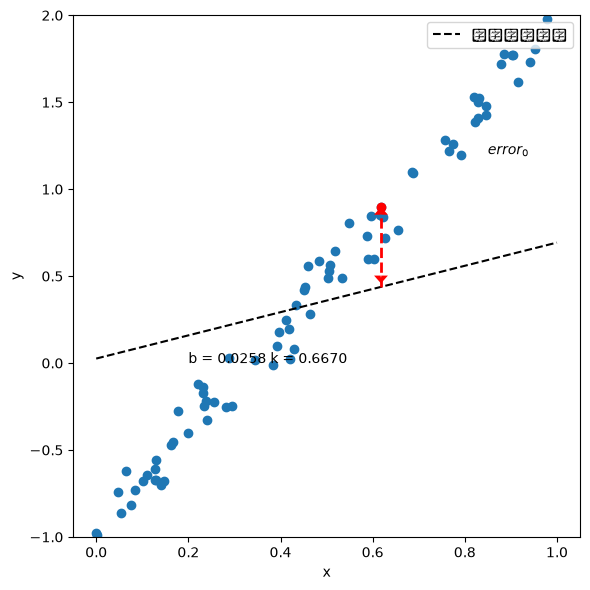

In [41]:
def figure2(x_train, y_train, b, w, color="k"):
    # Generates evenly spaced x feature
    x_range = np.linspace(0, 1, 101)
    # Computes yhat
    yhat_range = b + w * x_range

    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_ylim((-1, 2.0))

    # Dataset
    ax.scatter(x_train, y_train)
    # Predictions
    ax.plot(x_range, yhat_range, label="模型的预测值", c=color, linestyle="--")

    # Annotations
    ax.annotate(f"b = {b:.4f} k = {w:.4f}", xy=(0.2, 0), c=color)
    ax.legend(loc=0)
    fig.tight_layout()
    return fig, ax


def figure3(x_train, y_train, b, w):
    fig, ax = figure2(x_train, y_train, b, w)

    # First data point
    x0, y0 = x_train[0][0], y_train[0][0]
    # First data point
    ax.scatter([x0], [y0], c="r")
    # Vertical line showing error between point and prediction
    ax.plot([x0, x0], [(b + w * x0), y0 - 0.03], c="r", linewidth=2, linestyle="--")
    ax.arrow(
        x0,
        y0 - 0.03,
        0,
        0.03,
        color="r",
        shape="full",
        lw=0,
        length_includes_head=True,
        head_width=0.03,
    )
    yy = b + w * x0 + 0.05
    ax.arrow(
        x0,
        yy,
        0,
        -0.03,
        color="r",
        shape="full",
        lw=0,
        length_includes_head=True,
        head_width=0.03,
    )
    # Annotations
    ax.annotate(r"$error_0$", xy=(0.85, 1.2))

    fig.tight_layout()
    return fig, ax


figure3(x_train, y_train, b, k)

### **<font color=purple>计算损失</font>**
> ### 在机器学习中，把所有的残差进行统计分析，称为<font color="purple">**计算损失**</font>。另一方面，损失是一组数据的某种残差的聚合。接下来应该根据损失来<font color="purple">**调整参数k和b使得损失减小**</font>。因此似乎应该计算<font color="purple">**所有数据点（N个）的损失**</font>。计算所有(N)个数据点的损失是一种很稳定的做法，但也是一种很慢的做法。为了速度，可以牺牲一些稳定性。可以通过从N中<font color="purple">**随机选择(不重复)n的子集**</font>来完成每次损失的计算。根据选择的不同，分为以下3中情况，<font color="purple">**Batch mini-Batch，和随机梯度下降（Stochastic Gradient Descent，SGD）**</font>：

+ ### 如果使用训练集中的所有点(n = n)来计算损失，那么就是Batch梯度下降；
+ ### 如果每次使用单个点(n = 1)，它将是随机梯度下降(SGD)；
+ ### 在1和n之间的任何其他(n)都表示mini-Batch梯度下降。

> ### 对于回归问题，损失由<font color="purple">**均方差函数(MSE)**</font>给出；也就是所有平方差的平均值。也就是说，所有标签（label y）和预测结果（kx+b）之差的平方的平均值：


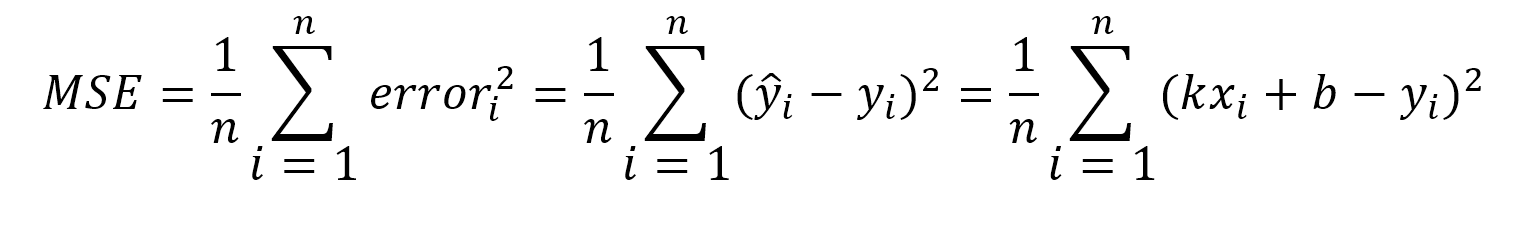

In [42]:
error = yhat - y_train
loss = (error**2).mean()
loss

np.float64(0.4397971709787784)

我们刚刚计算出随机初始化参数（b = 0.49，w = -0.13）对应的损失值（2.74）。如果我们对**所有**可能的b和w取值都执行相同计算会怎么样？当然，并非取全部可能的值，而是选取指定范围内等间隔数值的所有组合.

得到的结果是一个损失网格，每一个损失值对应参数b和w的一组不同组合。
这些损失构成了我们的损失曲面，可以通过三维图像可视化，其中纵轴（z轴）代表损失值。如果我们把能产生相同损失值的b和w参数组合连接起来，就会得到一个椭圆。随后，我们可以在原始的b-w平面上绘制这个椭圆（蓝色，对应损失值为3）。简而言之，这就是等高线图的作用。接下来，我们将始终使用等高线图，而不是对应的三维图像。

![](../pictures/losssurface0.png)

我们可以在损失函数曲面上截取一个截面，查看固定另一个参数时损失值的变化情况。
首先令 b = 0.52（该值取自b取值范围，是最接近b初始随机值0.4967的数）。我们在左侧损失函数图像上沿竖直方向截取截面（红色虚线），就得到右侧对应的图像

![](../pictures/losssurface1.png)

![](../pictures/losssurface2.png)

一般来说，该截面分析的目的是：保持其他所有量不变，只改变单个参数，从而得到损失的变化。简单来讲，这就是梯度。

### **<font color=purple>梯度下降</font>**
+ ### 现在，我们的目标是调整k和b的值，使得损失减少。
+ ### 也就是说，从当前位置，沿着MSE函数的<font color="purple">**梯度下降**</font>的方向来调整k和b的值。
+ ### 为此，需要<font color="purple">**求出MSE的梯度**</font>。由于MSE是关于k和b的二元函数，因此梯度将是一个偏导数：

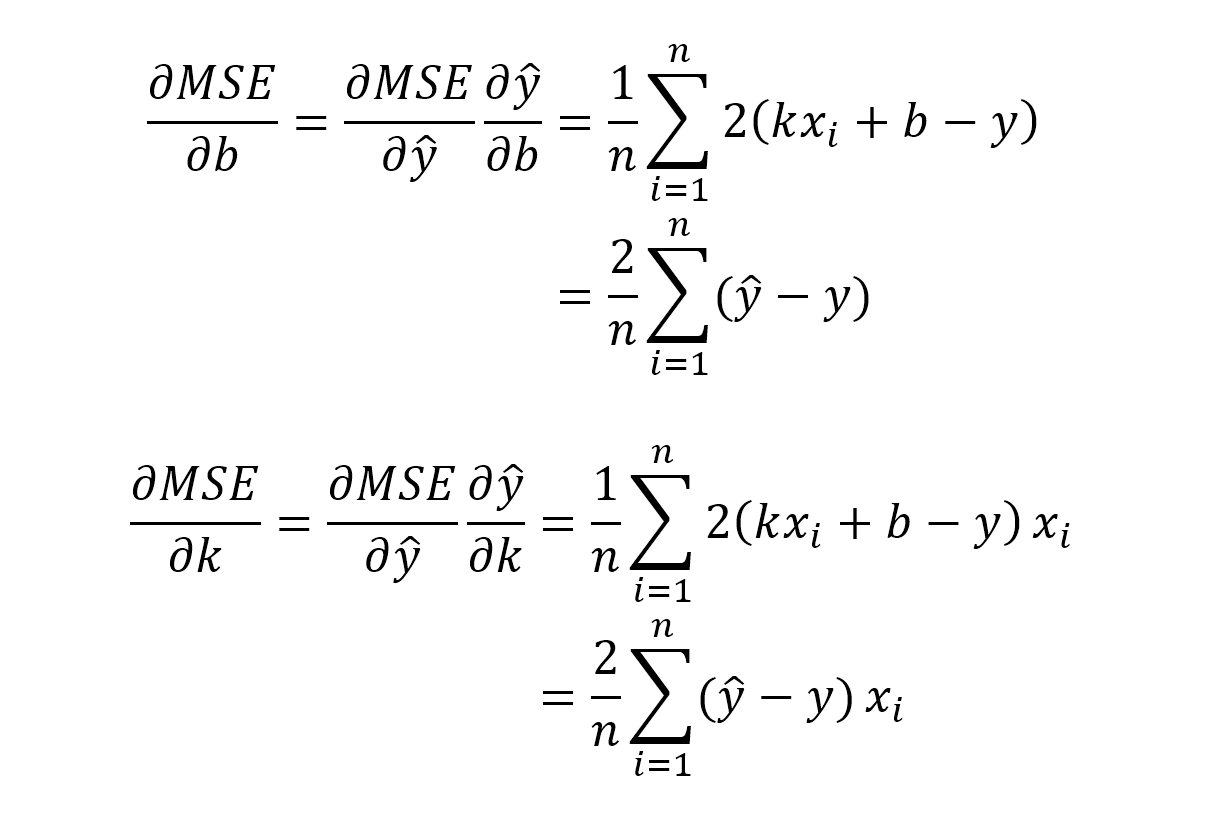

In [43]:
b_grad = 2 * error.mean()
k_grad = 2 * (x_train * error).mean()
print("b_grad = ", b_grad, "k_grad = ", k_grad)


b_grad =  -0.14244351071000183 k_grad =  -0.43882175457964256


### **<font color=purple>参数更新</font>**
+ ### 计算出梯度之后，就可以更新k和b这两个参数了。
+ ### 当然更新的<font color="purple">**目的**</font>是使得loss减小：


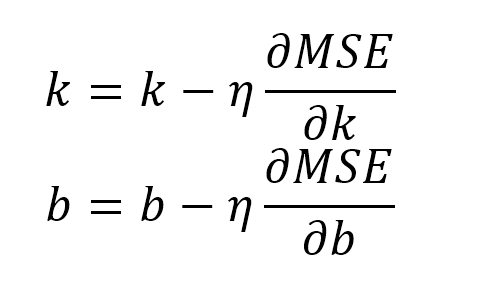

In [44]:
b = b - 0.1 * b_grad
k = k - 0.1 * k_grad
print("b=", b, "k=", k)

b= 0.040057432137274 k= 0.7108702318114326


C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3

(<Figure size 600x600 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

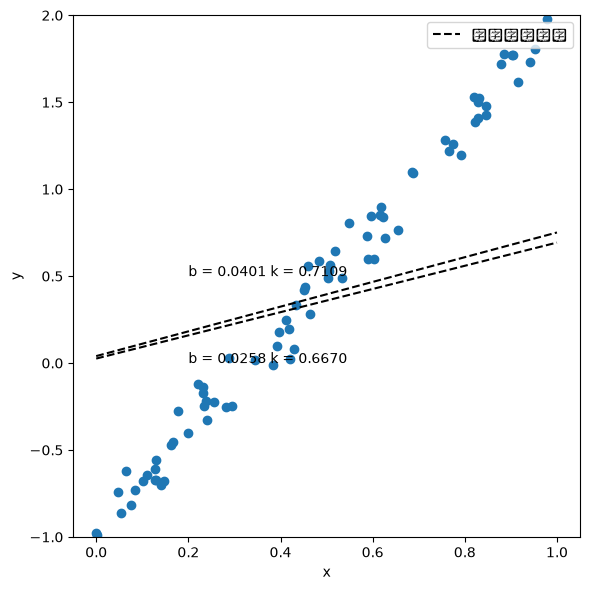

In [45]:
def figure4(x_train, y_train, b, w):
    np.random.seed(23)
    k_initial = np.random.randn()
    b_initial = np.random.randn()

    fig, ax = figure2(x_train, y_train, b_initial, k_initial)

    # Generates evenly spaced x feature
    x_range = np.linspace(0, 1, 101)
    # Model's predictions for updated paramaters
    yhat_range = b + w * x_range
    # Updated predictions
    ax.plot(
        x_range,
        yhat_range,
        label="Using parameters\nafter one update",
        c="k",
        linestyle="--",
    )
    # Annotations
    ax.annotate(f"b = {b:.4f} k = {w:.4f}", xy=(0.2, 0.5), c="k")

    fig.tight_layout()
    return fig, ax


figure4(x_train, y_train, b, k)

In [46]:
# Step 1 初始化参数
np.random.seed(23)
b = np.random.randn()
k = np.random.randn()

print(b, k)

# 学习率
lr = 0.1
# epochs
n_epochs = 1000

for epoch in range(n_epochs):
    # Step 2 预测输出
    yhat = b + k * x_train

    # Step 3 计算损失
    error = yhat - y_train

    loss = (error**2).mean()

    # Step 3 计算梯度
    b_grad = 2 * error.mean()
    k_grad = 2 * (x_train * error).mean()

    # Step 4 更新参数

    b = b - lr * b_grad
    k = k - lr * k_grad

print(b, k)

0.6669880563534684 0.02581308106627382
-0.9792691404201709 2.9492383613575557


C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3988\861906568.py:20: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\2\ipykernel_3

(<Figure size 600x600 with 1 Axes>, <Axes: xlabel='x', ylabel='y'>)

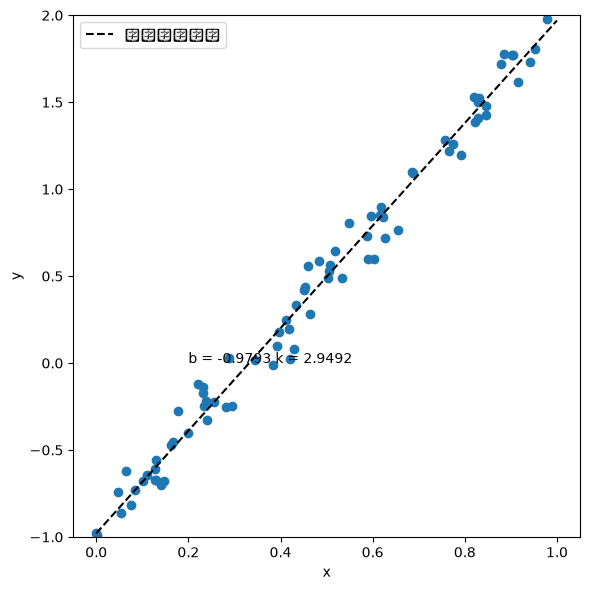

In [47]:
figure2(x_train, y_train, b, k)